# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** _________Kavya Sree Gudiwada____________
**Roll Number:** ____AP24110010791________________
**Date:** ____09/10/2026__________________

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [ ]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:*

A 70/30 split has higher entropy than a 90/10 split.
Entropy measures how unpredictable the label is.

If we calculate entropy of 70/30 split h(S)=-[0.7log2 0.7 + 0.3log2 0.3] = 0.881

For 90/10 the entropy h(S) = -[0.9log2 0.9 + 0.1 log2 0.1]= 0.469

So, 70/30 split has high entropy than 90/10 split.
Entropy measures the impurity.

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [ ]:
# Write your answer here

import math
def entropy(yes, no):
    total = yes + no
    result = 0

    for count in [yes, no]:
        if count != 0:
            p = count / total
            result -= p * math.log2(p)

    return result

parent_entropy = entropy(8, 6)

left_entropy = entropy(6, 0)
right_entropy = entropy(2, 6)

weighted_entropy = (6/14) * left_entropy + (8/14) * right_entropy

information_gain = parent_entropy - weighted_entropy

print("Parent Entropy:", round(parent_entropy, 4))
print("Left Child Entropy:", round(left_entropy, 4))
print("Right Child Entropy:", round(right_entropy, 4))
print("Weighted Entropy:", round(weighted_entropy, 4))
print("Information Gain:", round(information_gain, 4))



Parent Entropy: 0.9852
Left Child Entropy: 0.0
Right Child Entropy: 0.8113
Weighted Entropy: 0.4636
Information Gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [ ]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [ ]:

import math
def entropy(counts):
    total = counts.sum()
    result = 0

    for count in counts:
        if count > 0:
            p = count / total
            result -= p * math.log2(p)

    return result


def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0

    for value, subset in df.groupby(attribute):
        weighted += (len(subset) / len(df)) * entropy(
            subset[target].value_counts()
        )

    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [ ]:
# Write your answer here

import math
import pandas as pd

def entropy(counts):
    total = counts.sum()
    result = 0

    for count in counts:
        if count > 0:
            p = count / total
            result -= p * math.log2(p)

    return result

def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0

    for value, subset in df.groupby(attribute):
        weighted += (len(subset) / len(df)) * entropy(
            subset[target].value_counts()
        )

    return total - weighted
attributes = ['Outlook', 'Temperature', 'Humidity']

print("Root Entropy:",
      round(entropy(tennis['Play'].value_counts()), 4))

for attribute in attributes:
    print(f"Gain({attribute}):",
          round(info_gain(tennis, attribute), 4))

root = max(attributes, key=lambda a: info_gain(tennis, a))
print("\nRoot attribute:", root)

for value, subset in tennis.groupby(root):
    print(f"\n{root} = {value}")
    print("Play counts:")
    print(subset['Play'].value_counts())

    if subset['Play'].nunique() == 1:
        print("Pure branch")
    else:
        remaining = [a for a in ['Outlook', 'Temperature',
                                  'Humidity', 'Wind'] if a != root]

        for attribute in remaining:
            print(f"Gain({attribute}):",
                  round(info_gain(subset, attribute), 4))

        best = max(remaining, key=lambda a: info_gain(subset, a))
        print("Next split:", best)


Root Entropy: 0.9403
Gain(Outlook): 0.2467
Gain(Temperature): 0.0292
Gain(Humidity): 0.1518

Root attribute: Outlook

Outlook = Overcast
Play counts:
Play
Yes    4
Name: count, dtype: int64
Pure branch

Outlook = Rain
Play counts:
Play
Yes    3
No     2
Name: count, dtype: int64
Gain(Temperature): 0.02
Gain(Humidity): 0.02
Gain(Wind): 0.971
Next split: Wind

Outlook = Sunny
Play counts:
Play
No     3
Yes    2
Name: count, dtype: int64
Gain(Temperature): 0.571
Gain(Humidity): 0.971
Gain(Wind): 0.02
Next split: Humidity


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:*  A pure branch needs no further splitting because all the samples in that branch belong to the same class. For example, all samples with Outlook = Overcast have Play = Yes. So, the entropy is 0,the decision tree can directly predict Yes without splitting further.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


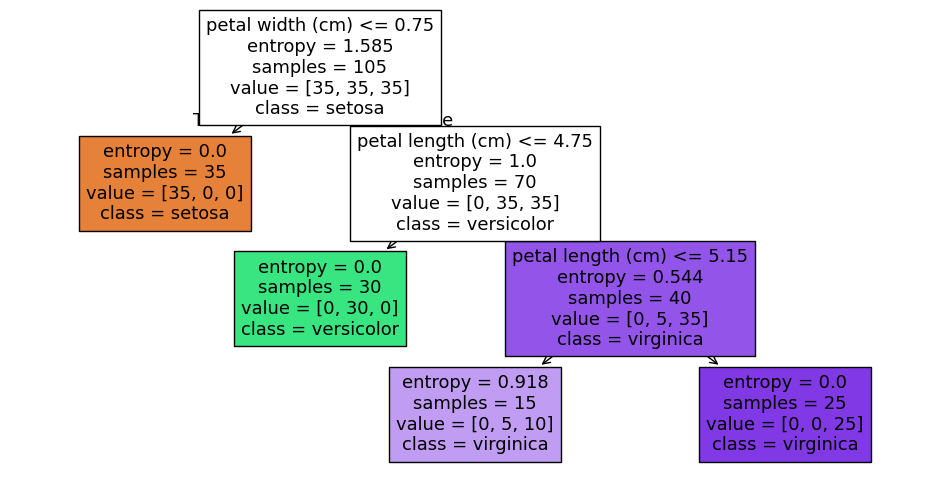

In [ ]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


 Max Depth  Train Accuracy  Test Accuracy
         1        0.777778            0.4
         2        0.888889            0.4
         3        1.000000            0.4
         4        1.000000            0.4
         5        1.000000            0.4
         6        1.000000            0.4
         7        1.000000            0.4
         8        1.000000            0.4
         9        1.000000            0.4
        10        1.000000            0.4
        11        1.000000            0.4
        12        1.000000            0.4
        13        1.000000            0.4
        14        1.000000            0.4
        15        1.000000            0.4

Best depth: 1
Best test accuracy: 0.4


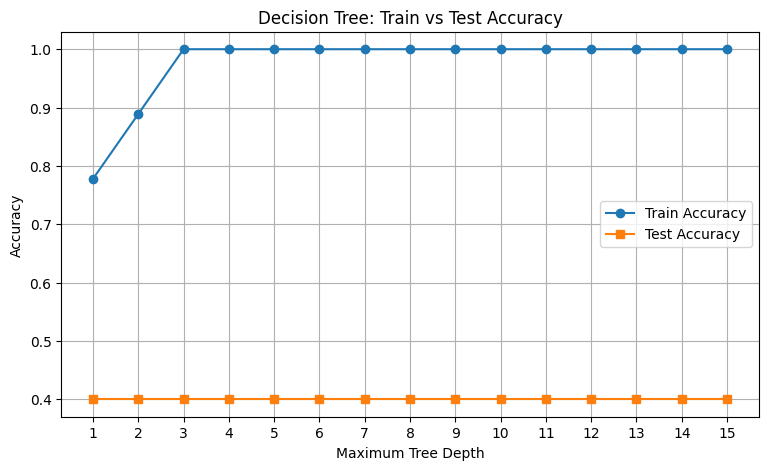

In [ ]:
X = tennis.drop('Play', axis=1)
y = tennis['Play']

X = pd.get_dummies(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

train_accuracies = []
test_accuracies = []
depths = range(1, 16)
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_accuracies.append(accuracy_score(y_train, train_pred))
    test_accuracies.append(accuracy_score(y_test, test_pred))

results = pd.DataFrame({
    'Max Depth': list(depths),
    'Train Accuracy': train_accuracies,
    'Test Accuracy': test_accuracies
})

print(results.to_string(index=False))

best_index = test_accuracies.index(max(test_accuracies))
best_depth = list(depths)[best_index]

print("\nBest depth:", best_depth)
print("Best test accuracy:", round(test_accuracies[best_index], 4))

plt.figure(figsize=(9, 5))
plt.plot(list(depths), train_accuracies, marker='o',
         label='Train Accuracy')
plt.plot(list(depths), test_accuracies, marker='s',
         label='Test Accuracy')

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Train vs Test Accuracy')
plt.xticks(list(depths))
plt.grid(True)
plt.legend()
plt.show()


**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:* Week 6 knob was the number of features, and Week 7 was the number of iterations. At the lower extreme, the model may underfit; at the higher extreme, it may become too complex or overfit.


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [ ]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)
# K=3
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


In [4]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

digits = load_digits()
X = digits.data
y = digits.target

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)

y_pred = tree.predict(Xd_test)
print("Test Accuracy:", accuracy_score(yd_test, y_pred))

Test Accuracy: 0.8648148148148148


In [5]:
for depth in [3, 6, 10]:
    tree = DecisionTreeClassifier(
        criterion='entropy',
        max_depth=depth,
        random_state=1
    )
    tree.fit(Xd_train, yd_train)
    y_pred = tree.predict(Xd_test)

    print(f"max_depth={depth}, Test Accuracy={accuracy_score(yd_test, y_pred):.4f}")

max_depth=3, Test Accuracy=0.5574
max_depth=6, Test Accuracy=0.8019
max_depth=10, Test Accuracy=0.8648


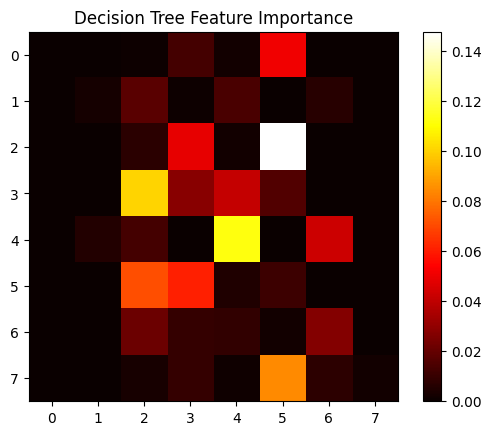

In [6]:
import matplotlib.pyplot as plt

importance = tree.feature_importances_.reshape(8, 8)

plt.imshow(importance, cmap='hot')
plt.colorbar()
plt.title("Decision Tree Feature Importance")
plt.show()

**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:* The decision tree is usually less accurate than KNN because it relies on selected important pixels, while KNN compares the overall pixel patterns of images.


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [7]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [9]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(vocabulary=vocab)

sentences = [
    'the striker scored a goal',
    'the team won the match'
]

X_new = vectorizer.transform(sentences)
predictions = tree.predict(X_new)

for sentence, prediction in zip(sentences, predictions):
    print(sentence, "->", prediction)

the striker scored a goal -> sports
the team won the match -> sports


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:* No, the split words may change. A tree trained on very little data may not always give correct predictions.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
